# Bước A4 (phần so sánh) - gom 3 lần huấn luyện lại Sequential Forecast LSTM có Q (hạt giống 111, 222, 333), so với best_model.pt của tác giả BiasCast, đo nhiễu hạt giống, xuất dự báo theo hợp đồng NPZ của bộ đánh giá
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/03_Pipeline.md Mục 7 (dòng A4), 9.5.
 Notebook Kaggle "04_A4_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = On, Persistence = Files only,
 Environment = Pin to original environment. Add Input:
   - Output 3 notebook 03_A4_LamaHCEExt_Retrain_Seed111 (Version 1), _Seed222 (Version 2), _Seed333 (Version 2);
   - Output 02_A3_LamaHCEExt_Benchmarks (người 1, Version 1) - ngữ cảnh quan trắc, persistence, diện tích;
   - Dataset lamah-ce-ext - chỉ số test của tác giả.
 Không cần GPU, không cần thư viện NeuralHydrology: test_results.p chỉ cần xarray để đọc (giống bộ đánh giá đọc A2,
 Workspace/06_Evaluation/01_Evaluation_LamaHCEExt.py dòng 591-631).
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Input, kiểm sha256 tệp của 3 hạt giống, môi trường
   Phần 2 - Bảng 3 hạt giống và tác giả, xét điều kiện A4
   Phần 3 - So từng lưu vực, mức nhiễu hạt giống
   Phần 4 - Hình
   Phần 5 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
   Phần 6 - Lưu kết quả và môi trường 

# Phần 1 - Tìm Input, kiểm sha256 tệp của 3 hạt giống, môi trường
 Mỗi notebook hạt giống có a4_output/environment.json (hạt giống, thư mục run, commit thư viện) và a4_output/manifest.csv
 (6 tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó). Tìm 3 thư mục đó trong Input, tính
 lại sha256 từng tệp để chắc Input gắn đúng bản lưu và không hỏng khi chép. Tìm thêm 2 tệp ngữ cảnh của A3
 (A3_persistence_predictions.npz, A3_Q_source_window.npz - tên theo 02_A3_LamaHCEExt_Benchmarks.py dòng 805, 964) và
 chỉ số test của tác giả (cùng run A2, A4 dùng). Phần 1 chưa đạt thì dừng notebook.

In [1]:
# %% Phần 1 - Tìm Input, kiểm sha256 tệp của 3 hạt giống, môi trường
# Mỗi notebook hạt giống có a4_output/environment.json (hạt giống, thư mục run, commit thư viện) và a4_output/manifest.csv
# (6 tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó). Tìm 3 thư mục đó trong Input, tính
# lại sha256 từng tệp để chắc Input gắn đúng bản lưu và không hỏng khi chép. Tìm thêm 2 tệp ngữ cảnh của A3
# (A3_persistence_predictions.npz, A3_Q_source_window.npz - tên theo 02_A3_LamaHCEExt_Benchmarks.py dòng 805, 964) và
# chỉ số test của tác giả (cùng run A2, A4 dùng). Phần 1 chưa đạt thì dừng notebook.
import hashlib
import json
import os
import platform
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("A4_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "a4_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("a4_compare_work")
OUT_DIR = WORK_DIR / "a4_compare"
SEEDS = [111, 222, 333]
SEED_VERSIONS = {111: 1, 222: 2, 333: 2}  # bản lưu chính thức trên Kaggle (Save & Run All 23-24/10/2026)
A3_VERSION = 1
NH_COMMIT = "dda45fcf19ee7ffd481b9d192778539df46fb074"
A3_FILES = ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]
AUTHOR_METRICS_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                      "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv")
ENV_LIBS = ["numpy", "pandas", "xarray", "scipy", "matplotlib"]
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def short(path, keep=3):
    # Đường dẫn tính từ INPUT_ROOT, dài thì giữ 2 cấp đầu và `keep` cấp cuối.
    parts = Path(path).relative_to(INPUT_ROOT).parts
    return "/".join(parts) if len(parts) <= keep + 2 else "/".join(parts[:2] + ("...",) + parts[-keep:])


def unique_file(root, name):
    # Đúng một tệp tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều (gắn trùng Input).
    hits = sorted(root.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 tệp '{name}' dưới {root}, thấy {len(hits)}: {hits}")
    return hits[0]


# (1) Thư mục output của 3 notebook hạt giống: nhận theo environment.json, không theo tên đường dẫn
SEED_ROOTS = {}
for env_path in sorted(INPUT_ROOT.rglob("a4_output/environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    if env.get("seed") in SEED_ROOTS:
        raise RuntimeError(f"Hạt giống {env['seed']} có ở 2 Input: {SEED_ROOTS[env['seed']]}, {env_path.parent.parent}")
    SEED_ROOTS[env.get("seed")] = env_path.parent.parent  # thư mục tương ứng /kaggle/working của notebook đó
if sorted(SEED_ROOTS) != SEEDS:
    raise RuntimeError(f"Cần Output của đúng 3 notebook hạt giống {SEEDS}, thấy {sorted(SEED_ROOTS)} - kiểm Add Input")
SEED_ENV = {s: json.loads((r / "a4_output" / "environment.json").read_text(encoding="utf-8")) for s, r in SEED_ROOTS.items()}
show("Output 3 notebook hạt giống", pd.DataFrame([{
    "hạt giống": s, "Version": SEED_VERSIONS.get(s), "thư mục Input": short(SEED_ROOTS[s]),
    "thư mục run": e["run_dir"], "commit thư viện": e["neuralhydrology_commit"][:7], "GPU": e["gpu"],
    "torch": e["libs"]["torch"], "epoch best_model.pt": e["summary"]["saved_epoch"],
    "số epoch": e["summary"]["n_epochs"]} for s, e in sorted(SEED_ENV.items())]))

# (2) Kiểm sha256 từng tệp trong manifest.csv
rows = []
for s, root in sorted(SEED_ROOTS.items()):
    man = pd.read_csv(root / "a4_output" / "manifest.csv")
    for rel, digest in zip(man["tệp"], man["sha256"]):
        f = root / rel
        got = sha256(f) if f.exists() else "THIẾU"
        rows.append({"hạt giống": s, "tệp": rel.split("/", 2)[-1], "KB": round(f.stat().st_size / 1e3, 1) if f.exists() else None,
                     "sha256 khớp": "ĐẠT" if got == digest else "KHÔNG"})
SHA_DF = pd.DataFrame(rows)
show("sha256 tệp chính của 3 run (so với manifest.csv của từng notebook)",
     SHA_DF.pivot(index="tệp", columns="hạt giống", values="sha256 khớp").reset_index())

# (3) Ngữ cảnh A3 và chỉ số test của tác giả
A3_PATHS = {name: unique_file(INPUT_ROOT, name) for name in A3_FILES}
author_hits = [p for p in INPUT_ROOT.rglob("test_metrics.csv") if p.as_posix().endswith(AUTHOR_METRICS_REL)]
if len(author_hits) != 1:
    raise FileNotFoundError(f"Cần đúng 1 tệp chỉ số test của tác giả ({AUTHOR_METRICS_REL}), thấy {len(author_hits)} - gắn lamah-ce-ext")
AUTHOR_METRICS_PATH = author_hits[0]
show("Tệp ngữ cảnh", pd.DataFrame(
    [{"tệp": n, "đường dẫn": short(p), "KB": round(p.stat().st_size / 1e3, 1)} for n, p in A3_PATHS.items()]
    + [{"tệp": "test_metrics.csv của tác giả", "đường dẫn": short(AUTHOR_METRICS_PATH),
        "KB": round(AUTHOR_METRICS_PATH.stat().st_size / 1e3, 1)}]), digits=1)

# (4) Môi trường của notebook này
ENV = {"Python": platform.python_version(), **{lib: metadata.version(lib) for lib in ENV_LIBS},
       "Số CPU": os.cpu_count(), "Ngày dựng ảnh Kaggle":
       Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"}
show("Môi trường", pd.DataFrame({"mục": list(ENV), "giá trị": [str(v) for v in ENV.values()]}))

checks = [("Đủ 3 hạt giống 111, 222, 333", sorted(SEED_ROOTS), SEEDS, sorted(SEED_ROOTS) == SEEDS),
          ("Mỗi hạt giống đủ 6 tệp chính", SHA_DF.groupby("hạt giống").size().to_dict(), "6 mỗi hạt giống",
           SHA_DF.groupby("hạt giống").size().eq(6).all() and len(SHA_DF) == 18),
          ("sha256 khớp manifest", f"{int((SHA_DF['sha256 khớp'] == 'ĐẠT').sum())} / {len(SHA_DF)}", "tất cả",
           (SHA_DF["sha256 khớp"] == "ĐẠT").all()),
          ("Cùng commit thư viện dda45fc", sorted({e["neuralhydrology_commit"][:7] for e in SEED_ENV.values()}), NH_COMMIT[:7],
           all(e["neuralhydrology_commit"] == NH_COMMIT for e in SEED_ENV.values())),
          ("Cùng phiên bản torch", sorted({e["libs"]["torch"] for e in SEED_ENV.values()}), "1 bản",
           len({e["libs"]["torch"] for e in SEED_ENV.values()}) == 1)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Input rồi chạy lại")
print("=> Đạt. Chạy Phần 2.")


hạt giống,Version,thư mục Input,thư mục run,commit thư viện,GPU,torch,epoch best_model.pt,số epoch
111,1,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed111,a4_runs/A4_SeqLSTM_Q_seed111_2310_193149,dda45fc,Tesla T4,2.11.0+cu128,11,16
222,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed222,a4_runs/A4_SeqLSTM_Q_seed222_2310_194052,dda45fc,Tesla T4,2.11.0+cu128,15,20
333,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed333,a4_runs/A4_SeqLSTM_Q_seed333_2310_232038,dda45fc,Tesla T4,2.11.0+cu128,14,19


tệp,111,222,333
best_model.pt,ĐẠT,ĐẠT,ĐẠT
config.yml,ĐẠT,ĐẠT,ĐẠT
output.log,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_metrics.csv,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_results.p,ĐẠT,ĐẠT,ĐẠT
train_data/train_data_scaler.yml,ĐẠT,ĐẠT,ĐẠT


tệp,đường dẫn,KB
A3_persistence_predictions.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_persistence_predictions.npz,8136.7
A3_Q_source_window.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_Q_source_window.npz,3349.0
test_metrics.csv của tác giả,datasets/hunhngcthng/.../test/best_model/test_metrics.csv,18.8


mục,giá trị
Python,3.13.15
numpy,2.1.3
pandas,2.3.3
xarray,2025.12.0
scipy,1.16.3
matplotlib,3.10.0
Số CPU,4
Ngày dựng ảnh Kaggle,20261022-041801


mục,giá trị,cần,đạt
"Đủ 3 hạt giống 111, 222, 333","[111, 222, 333]","[111, 222, 333]",ĐẠT
Mỗi hạt giống đủ 6 tệp chính,"{111: 6, 222: 6, 333: 6}",6 mỗi hạt giống,ĐẠT
sha256 khớp manifest,18 / 18,tất cả,ĐẠT
Cùng commit thư viện dda45fc,['dda45fc'],dda45fc,ĐẠT
Cùng phiên bản torch,['2.11.0+cu128'],1 bản,ĐẠT


=> Đạt. Chạy Phần 2.


# hần 2 - Bảng 3 hạt giống và tác giả, xét điều kiện A4
 Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv, đã kiểm sha256 ở Phần 1) và
 NSE validation theo epoch (a4_output/validation_curve_seed{N}.csv), tính lại trung vị rồi đối chiếu summary_seed{N}.json
 do notebook hạt giống ghi. Điều kiện đạt A4 (Plans/02_A4_Retrain.md): NSE trung vị test của tác giả nằm trong
 [min, max] của 3 hạt giống hoặc cách trung bình không quá 2 độ lệch chuẩn (ddof=1). Trung vị bỏ NaN như logger.py
 dòng 210 của thư viện.

In [2]:
# %% Phần 2 - Bảng 3 hạt giống và tác giả, xét điều kiện A4
# Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv, đã kiểm sha256 ở Phần 1) và
# NSE validation theo epoch (a4_output/validation_curve_seed{N}.csv), tính lại trung vị rồi đối chiếu summary_seed{N}.json
# do notebook hạt giống ghi. Điều kiện đạt A4 (Plans/02_A4_Retrain.md): NSE trung vị test của tác giả nằm trong
# [min, max] của 3 hạt giống hoặc cách trung bình không quá 2 độ lệch chuẩn (ddof=1). Trung vị bỏ NaN như logger.py
# dòng 210 của thư viện.
A4_Z_MAX = 2.0
SUM_TOL = 1e-9  # trung vị tính lại so với summary_seed{N}.json


def read_metrics(path):
    # test_metrics.csv của NeuralHydrology: cột đầu là mã lưu vực => chuẩn hóa thành str(int) như bộ đánh giá.
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    return m


SEED_SUMMARY = {s: json.loads((SEED_ROOTS[s] / "a4_output" / f"summary_seed{s}.json").read_text(encoding="utf-8"))
                for s in SEEDS}
SEED_METRICS = {s: read_metrics(SEED_ROOTS[s] / SEED_ENV[s]["run_dir"] / "test" / "best_model" / "test_metrics.csv")
                for s in SEEDS}
VAL_CURVES = {s: pd.read_csv(SEED_ROOTS[s] / "a4_output" / f"validation_curve_seed{s}.csv") for s in SEEDS}
AUTHOR_METRICS = read_metrics(AUTHOR_METRICS_PATH)
AUTHOR_NSE = float(AUTHOR_METRICS["NSE"].median())

rows = []
for s in SEEDS:
    m, sm = SEED_METRICS[s], SEED_SUMMARY[s]
    val = VAL_CURVES[s].set_index("epoch")["NSE trung vị validation (tệp)"]
    rows.append({"mô hình": f"hạt giống {s}", "epoch best_model.pt": sm["saved_epoch"],
                 "epoch NSE validation cao nhất": sm["true_best_epoch"], "số epoch đã chạy": sm["n_epochs"],
                 "giờ huấn luyện": sm["train_hours"], "NSE trung vị validation": float(val[sm["saved_epoch"]]),
                 "NSE trung vị test": float(m["NSE"].median()), "KGE trung vị test": float(m["KGE"].median()),
                 "lưu vực": len(m), "lưu vực có NSE": int(m["NSE"].notna().sum()),
                 "lưu vực NaN": ", ".join(m.index[m["NSE"].isna()]) or "-"})
rows.append({"mô hình": "tác giả (best_model.pt, Zenodo)", "NSE trung vị test": AUTHOR_NSE,
             "KGE trung vị test": float(AUTHOR_METRICS["KGE"].median()), "lưu vực": len(AUTHOR_METRICS),
             "lưu vực có NSE": int(AUTHOR_METRICS["NSE"].notna().sum()),
             "lưu vực NaN": ", ".join(AUTHOR_METRICS.index[AUTHOR_METRICS["NSE"].isna()]) or "-"})
SEED_TABLE = pd.DataFrame(rows).astype({c: "Int64" for c in ["epoch best_model.pt", "epoch NSE validation cao nhất",
                                                             "số epoch đã chạy"]})
SEED_TABLE["Δ NSE test so với tác giả"] = SEED_TABLE["NSE trung vị test"] - AUTHOR_NSE
show("Test 2014-2017: 3 hạt giống và tác giả (best_model.pt của mỗi run)", SEED_TABLE)

# Thống kê qua 3 hạt giống và điều kiện A4
seed_rows = SEED_TABLE.iloc[:len(SEEDS)]
STATS = pd.DataFrame([{"chỉ số": c, "trung bình": seed_rows[c].mean(), "độ lệch chuẩn (ddof=1)": seed_rows[c].std(ddof=1),
                       "min": seed_rows[c].min(), "max": seed_rows[c].max(), "max - min": seed_rows[c].max() - seed_rows[c].min()}
                      for c in ["NSE trung vị validation", "NSE trung vị test", "KGE trung vị test", "giờ huấn luyện"]])
show("Qua 3 hạt giống", STATS)
nse = STATS.set_index("chỉ số").loc["NSE trung vị test"]
A4_Z = (AUTHOR_NSE - nse["trung bình"]) / nse["độ lệch chuẩn (ddof=1)"]
in_range = nse["min"] <= AUTHOR_NSE <= nse["max"]

checks = [("Mỗi hạt giống đủ lưu vực như tác giả", [len(SEED_METRICS[s]) for s in SEEDS], len(AUTHOR_METRICS),
           all(set(SEED_METRICS[s].index) == set(AUTHOR_METRICS.index) for s in SEEDS)),
          ("NSE test tính lại khớp summary_seed{N}.json",
           [round(abs(float(SEED_METRICS[s]["NSE"].median()) - SEED_SUMMARY[s]["test_nse_median_best_model"]), 12) for s in SEEDS],
           f"<= {SUM_TOL}", all(abs(float(SEED_METRICS[s]["NSE"].median()) - SEED_SUMMARY[s]["test_nse_median_best_model"])
                                <= SUM_TOL for s in SEEDS)),
          ("Tác giả trong [min, max] của 3 hạt giống", f"{AUTHOR_NSE:.4f} so với [{nse['min']:.4f}, {nse['max']:.4f}]",
           "True (hoặc dòng dưới)", in_range),
          ("|Tác giả - trung bình| / độ lệch chuẩn", f"{abs(A4_Z):.2f}", f"<= {A4_Z_MAX}", abs(A4_Z) <= A4_Z_MAX)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
A4_PASS = in_range or abs(A4_Z) <= A4_Z_MAX
if not (checks[0][3] and checks[1][3]):
    raise RuntimeError("Phần 2 CHƯA đạt: dữ liệu 3 hạt giống không khớp (dòng KHÔNG ở trên) - kiểm Input")
print(f"=> Điều kiện A4: {'ĐẠT' if A4_PASS else 'KHÔNG ĐẠT'} (tác giả {AUTHOR_NSE:.4f}, 3 hạt giống "
      f"{nse['trung bình']:.4f} ± {nse['độ lệch chuẩn (ddof=1)']:.4f}, z = {A4_Z:+.2f}). Chạy Phần 3.")

mô hình,epoch best_model.pt,epoch NSE validation cao nhất,số epoch đã chạy,giờ huấn luyện,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực,lưu vực có NSE,lưu vực NaN,Δ NSE test so với tác giả
hạt giống 111,11,11,16,2.5000,0.7411,0.6952,0.7581,451,450,55,-0.0100
hạt giống 222,15,15,20,3.1667,0.7541,0.7038,0.7910,451,450,55,-0.0015
hạt giống 333,14,14,19,3.0833,0.7574,0.7059,0.7860,451,450,55,0.0006
"tác giả (best_model.pt, Zenodo)",-,-,-,-,-,0.7053,0.7671,451,450,55,0.0000


chỉ số,trung bình,độ lệch chuẩn (ddof=1),min,max,max - min
NSE trung vị validation,0.7509,0.0086,0.7411,0.7574,0.0163
NSE trung vị test,0.7016,0.0056,0.6952,0.7059,0.0106
KGE trung vị test,0.7783,0.0177,0.7581,0.7910,0.0329
giờ huấn luyện,2.9167,0.3632,2.5000,3.1667,0.6667


mục,giá trị,cần,đạt
Mỗi hạt giống đủ lưu vực như tác giả,"[451, 451, 451]",451,ĐẠT
NSE test tính lại khớp summary_seed{N}.json,"[0.0, 0.0, 0.0]",<= 1e-09,ĐẠT
"Tác giả trong [min, max] của 3 hạt giống","0.7053 so với [0.6952, 0.7059]",True (hoặc dòng dưới),ĐẠT
|Tác giả - trung bình| / độ lệch chuẩn,0.65,<= 2.0,ĐẠT


=> Điều kiện A4: ĐẠT (tác giả 0.7053, 3 hạt giống 0.7016 ± 0.0056, z = +0.65). Chạy Phần 3.


# Phần 3 - So từng lưu vực, mức nhiễu hạt giống
 (1) Bảng NSE từng lưu vực của 3 hạt giống và tác giả: độ lệch chuẩn, khoảng max - min qua 3 hạt giống, tác giả có nằm
 trong khoảng 3 hạt giống không. Nếu tác giả chỉ là "lần chạy thứ 4" cùng phân phối thì xác suất nằm trong [min, max]
 của 3 lần chạy là 2/4 = 0.5 (4 giá trị hoán đổi được, tác giả không phải nhỏ nhất hay lớn nhất).
 (2) Nhiễu theo mức NSE của lưu vực. (3) Kiểm định ghép cặp theo lưu vực: từng hạt giống với tác giả và từng cặp hạt
 giống với nhau - cùng cách của bộ đánh giá (01_Evaluation_LamaHCEExt.py Phần 7.1: Wilcoxon hai phía zero_method="wilcox",
 correction=False, method="auto"; Cohen's dz = trung bình hiệu / độ lệch chuẩn hiệu; Holm trong từng họ). Cặp hạt giống
 cho biết mô hình chỉ khác hạt giống đã chênh nhau bao nhiêu => mốc để đọc chênh lệch giữa các mô hình ở bước B, C.

In [3]:
# %% Phần 3 - So từng lưu vực, mức nhiễu hạt giống
# (1) Bảng NSE từng lưu vực của 3 hạt giống và tác giả: độ lệch chuẩn, khoảng max - min qua 3 hạt giống, tác giả có nằm
# trong khoảng 3 hạt giống không. Nếu tác giả chỉ là "lần chạy thứ 4" cùng phân phối thì xác suất nằm trong [min, max]
# của 3 lần chạy là 2/4 = 0.5 (4 giá trị hoán đổi được, tác giả không phải nhỏ nhất hay lớn nhất).
# (2) Nhiễu theo mức NSE của lưu vực. (3) Kiểm định ghép cặp theo lưu vực: từng hạt giống với tác giả và từng cặp hạt
# giống với nhau - cùng cách của bộ đánh giá (01_Evaluation_LamaHCEExt.py Phần 7.1: Wilcoxon hai phía zero_method="wilcox",
# correction=False, method="auto"; Cohen's dz = trung bình hiệu / độ lệch chuẩn hiệu; Holm trong từng họ). Cặp hạt giống
# cho biết mô hình chỉ khác hạt giống đã chênh nhau bao nhiêu => mốc để đọc chênh lệch giữa các mô hình ở bước B, C.
from scipy import stats

NSE_LEVELS = [-np.inf, 0.0, 0.5, 0.7, 0.85, np.inf]
NSE_LEVEL_NAMES = ["< 0", "0 - 0.5", "0.5 - 0.7", "0.7 - 0.85", ">= 0.85"]


def paired_test(left, right):
    # Chép từ bộ đánh giá Phần 7.1 (rút gọn trạng thái), dương = `left` tốt hơn.
    left, right = np.asarray(left, dtype=float), np.asarray(right, dtype=float)
    ok = np.isfinite(left) & np.isfinite(right)
    d = left[ok] - right[ok]
    sd = float(np.std(d, ddof=1)) if len(d) > 1 else np.nan
    p = 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided",
                                                        correction=False, method="auto").pvalue)
    return {"số cặp": len(d), "trái tốt hơn": int((d > 0).sum()), "trái kém hơn": int((d < 0).sum()),
            "trung bình hiệu": float(d.mean()), "trung vị hiệu": float(np.median(d)),
            "Cohen's dz": float(d.mean() / sd) if sd > 0 else np.nan, "p Wilcoxon": p}


def holm(p):
    # Holm-Bonferroni: p đã sắp tăng nhân (m - i), lấy max tích lũy, chặn ở 1.
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adj
    return out


# (1) Bảng từng lưu vực
seed_cols = [f"NSE {s}" for s in SEEDS]
BASIN_NOISE = pd.DataFrame({f"NSE {s}": SEED_METRICS[s]["NSE"] for s in SEEDS})
BASIN_NOISE["NSE tác giả"] = AUTHOR_METRICS["NSE"]
BASIN_NOISE = BASIN_NOISE.dropna()  # lưu vực có NSE ở cả 4 mô hình
BASIN_NOISE["trung bình 3 hạt giống"] = BASIN_NOISE[seed_cols].mean(axis=1)
BASIN_NOISE["độ lệch chuẩn 3 hạt giống"] = BASIN_NOISE[seed_cols].std(axis=1, ddof=1)
BASIN_NOISE["max - min 3 hạt giống"] = BASIN_NOISE[seed_cols].max(axis=1) - BASIN_NOISE[seed_cols].min(axis=1)
BASIN_NOISE["tác giả - trung bình"] = BASIN_NOISE["NSE tác giả"] - BASIN_NOISE["trung bình 3 hạt giống"]
BASIN_NOISE["tác giả trong [min, max]"] = BASIN_NOISE["NSE tác giả"].between(BASIN_NOISE[seed_cols].min(axis=1),
                                                                           BASIN_NOISE[seed_cols].max(axis=1))
BASIN_NOISE["mức NSE"] = pd.cut(BASIN_NOISE["trung bình 3 hạt giống"], NSE_LEVELS, labels=NSE_LEVEL_NAMES, right=False)
BASIN_NOISE.index.name = "basin"
BASIN_NOISE.to_csv(OUT_DIR / "A4_seed_noise_by_basin.csv")

q = [0.5, 0.75, 0.9, 1.0]
show(f"Nhiễu hạt giống theo lưu vực ({len(BASIN_NOISE)} lưu vực có NSE ở cả 4 mô hình)", pd.DataFrame(
    [{"đại lượng": c, **{f"phân vị {int(x * 100)}%": BASIN_NOISE[c].quantile(x) for x in q}}
     for c in ["độ lệch chuẩn 3 hạt giống", "max - min 3 hạt giống"]]
    + [{"đại lượng": "|tác giả - trung bình|", **{f"phân vị {int(x * 100)}%": BASIN_NOISE["tác giả - trung bình"].abs().quantile(x)
                                                  for x in q}}]))
print(f"Tác giả nằm trong [min, max] của 3 hạt giống ở {BASIN_NOISE['tác giả trong [min, max]'].mean():.1%} lưu vực "
      f"(nếu chỉ là lần chạy thứ 4 cùng phân phối: 50%).")

# (2) Theo mức NSE
show("Nhiễu hạt giống theo mức NSE của lưu vực (trung bình 3 hạt giống)", BASIN_NOISE.groupby("mức NSE", observed=False).agg(
    **{"số lưu vực": ("trung bình 3 hạt giống", "size"),
       "trung vị độ lệch chuẩn": ("độ lệch chuẩn 3 hạt giống", "median"),
       "trung vị max - min": ("max - min 3 hạt giống", "median"),
       "tỉ lệ tác giả trong [min, max]": ("tác giả trong [min, max]", "mean")}).reset_index())
show("10 lưu vực nhiễu hạt giống lớn nhất", BASIN_NOISE.nlargest(10, "max - min 3 hạt giống")[
    seed_cols + ["NSE tác giả", "max - min 3 hạt giống"]].reset_index())

# (3) Kiểm định ghép cặp theo lưu vực
pairs = {"hạt giống với tác giả": [(f"NSE {s}", "NSE tác giả") for s in SEEDS],
         "hạt giống với hạt giống": [(f"NSE {a}", f"NSE {b}") for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]]}
rows = []
for family, cols in pairs.items():
    res = [{"họ": family, "trái": l.replace("NSE ", ""), "phải": r.replace("NSE ", ""),
            **paired_test(BASIN_NOISE[l], BASIN_NOISE[r])} for l, r in cols]
    for r_, p_adj in zip(res, holm([r_["p Wilcoxon"] for r_ in res])):
        r_["p Holm"] = p_adj
    rows += res
PAIRED = pd.DataFrame(rows)
PAIRED.to_csv(OUT_DIR / "A4_paired_tests.csv", index=False)
show("Wilcoxon ghép cặp theo lưu vực (NSE test; dương = bên trái tốt hơn)", PAIRED)
seed_p = PAIRED.loc[PAIRED["họ"] == "hạt giống với hạt giống", "p Holm"]
print(f"=> Mốc nhiễu: trung vị độ lệch chuẩn NSE theo lưu vực {BASIN_NOISE['độ lệch chuẩn 3 hạt giống'].median():.4f}; "
      f"NSE trung vị toàn bộ trải {STATS.set_index('chỉ số').loc['NSE trung vị test', 'max - min']:.4f} giữa 3 hạt giống; "
      f"{int((seed_p < 0.05).sum())}/{len(seed_p)} cặp hạt giống có p Holm < 0.05 dù cùng mô hình => ở bước B, C chỉ p "
      "không đủ, phải so độ lớn chênh lệch với mốc nhiễu này. Trung bình hiệu và Cohen's dz bị kéo bởi lưu vực NSE âm sâu, "
      "đọc trung vị hiệu. Chạy Phần 4.")


đại lượng,phân vị 50%,phân vị 75%,phân vị 90%,phân vị 100%
độ lệch chuẩn 3 hạt giống,0.0207,0.0353,0.0644,3.9117
max - min 3 hạt giống,0.0396,0.0681,0.1212,7.4043
|tác giả - trung bình|,0.0171,0.0353,0.0611,69.3014


Tác giả nằm trong [min, max] của 3 hạt giống ở 52.2% lưu vực (nếu chỉ là lần chạy thứ 4 cùng phân phối: 50%).


mức NSE,số lưu vực,trung vị độ lệch chuẩn,trung vị max - min,"tỉ lệ tác giả trong [min, max]"
< 0,2,2.8648,5.3100,0.0000
0 - 0.5,68,0.0335,0.0647,0.5147
0.5 - 0.7,156,0.0265,0.0517,0.5128
0.7 - 0.85,154,0.0200,0.0383,0.5130
>= 0.85,70,0.0094,0.0182,0.5857


basin,NSE 111,NSE 222,NSE 333,NSE tác giả,max - min 3 hạt giống
758,-13.4255,-7.5357,-6.0213,-78.2956,7.4043
742,-5.8337,-2.6180,-2.7566,-43.9407,3.2156
312,0.4595,-0.0523,0.3811,0.4104,0.5118
119,0.2274,0.5499,0.1039,0.1171,0.4460
754,0.3897,0.0552,0.4974,-0.0197,0.4422
354,0.3094,0.7291,0.6255,0.4983,0.4197
523,0.6002,0.3753,0.7810,0.7699,0.4057
568,0.7130,0.6254,0.3114,0.6402,0.4016
411,-0.1164,0.2105,0.2402,0.2206,0.3566
590,0.5939,0.5037,0.8184,0.5131,0.3147


họ,trái,phải,số cặp,trái tốt hơn,trái kém hơn,trung bình hiệu,trung vị hiệu,Cohen's dz,p Wilcoxon,p Holm
hạt giống với tác giả,111,tác giả,450,209,241,0.2270,-0.0023,0.0641,0.0962,0.1925
hạt giống với tác giả,222,tác giả,450,248,202,0.2540,0.0037,0.0658,0.0480,0.1439
hạt giống với tác giả,333,tác giả,450,253,197,0.2563,0.0048,0.0654,0.1322,0.1925
hạt giống với hạt giống,111,222,450,197,253,-0.0270,-0.0038,-0.0835,0.0028,0.0084
hạt giống với hạt giống,111,333,450,196,254,-0.0293,-0.0044,-0.0766,0.0064,0.0129
hạt giống với hạt giống,222,333,450,234,216,-0.0023,0.0013,-0.0230,0.1887,0.1887


=> Mốc nhiễu: trung vị độ lệch chuẩn NSE theo lưu vực 0.0207; NSE trung vị toàn bộ trải 0.0106 giữa 3 hạt giống; 2/3 cặp hạt giống có p Holm < 0.05 dù cùng mô hình => ở bước B, C chỉ p không đủ, phải so độ lớn chênh lệch với mốc nhiễu này. Trung bình hiệu và Cohen's dz bị kéo bởi lưu vực NSE âm sâu, đọc trung vị hiệu. Chạy Phần 4.


# Phần 4 - Hình
 Hai hình gộp 3 hạt giống và tác giả (thay hình riêng từng hạt giống A4_Curve_Seed{N}, A4_CDF_Seed{N}):
 A4_Seeds.png - (a) NSE validation theo epoch, (b) NSE trung vị test và điều kiện A4;
 A4_BasinNoise.png - (a) CDF NSE theo lưu vực, (b) độ lệch chuẩn qua 3 hạt giống theo mức NSE của lưu vực.
 Chữ trong hình tiếng Anh, chú giải đặt ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới hình.

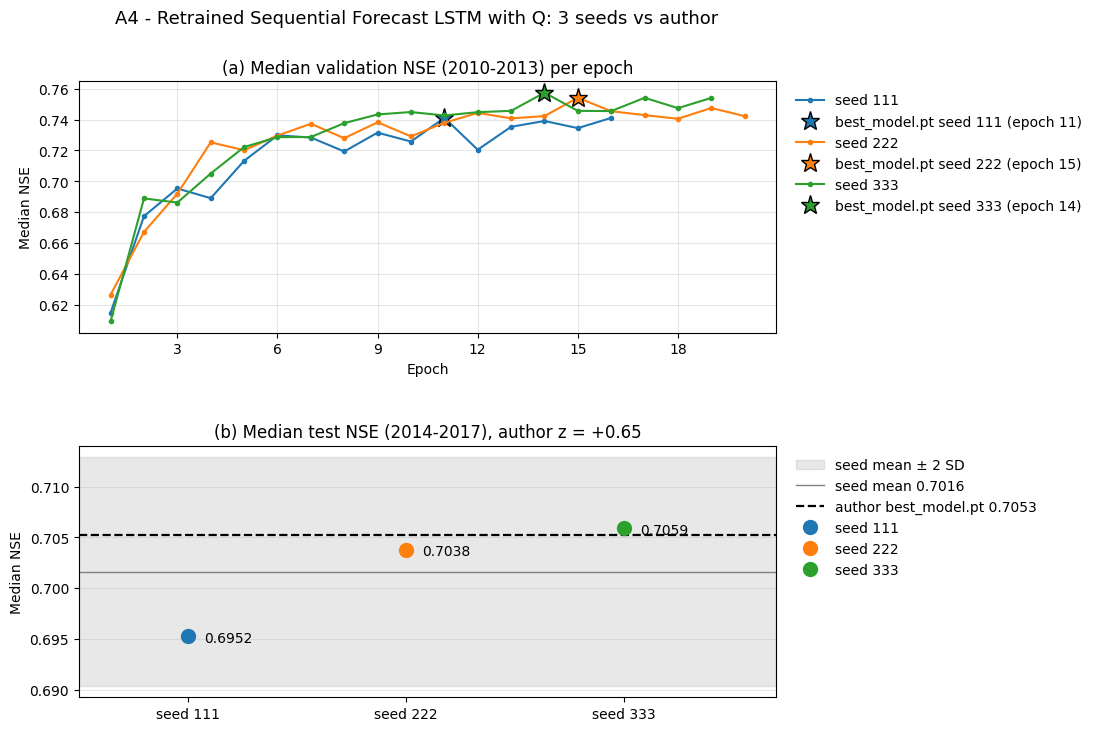

Hình: (a) NSE trung vị validation sau mỗi epoch của 3 hạt giống; ngôi sao là epoch được lưu thành best_model.pt (epoch 11, 15, 14), trùng epoch NSE validation cao nhất ở cả 3 hạt giống; đường dừng ở epoch dừng sớm. (b) NSE trung vị test của 3 hạt giống (chấm) so với best_model.pt của tác giả (nét đứt); dải xám là trung bình ± 2 độ lệch chuẩn của 3 hạt giống. Tác giả 0.7053 nằm trong [0.6952, 0.7059]: có; cách trung bình 0.65 độ lệch chuẩn => tái huấn luyện ĐẠT điều kiện A4.


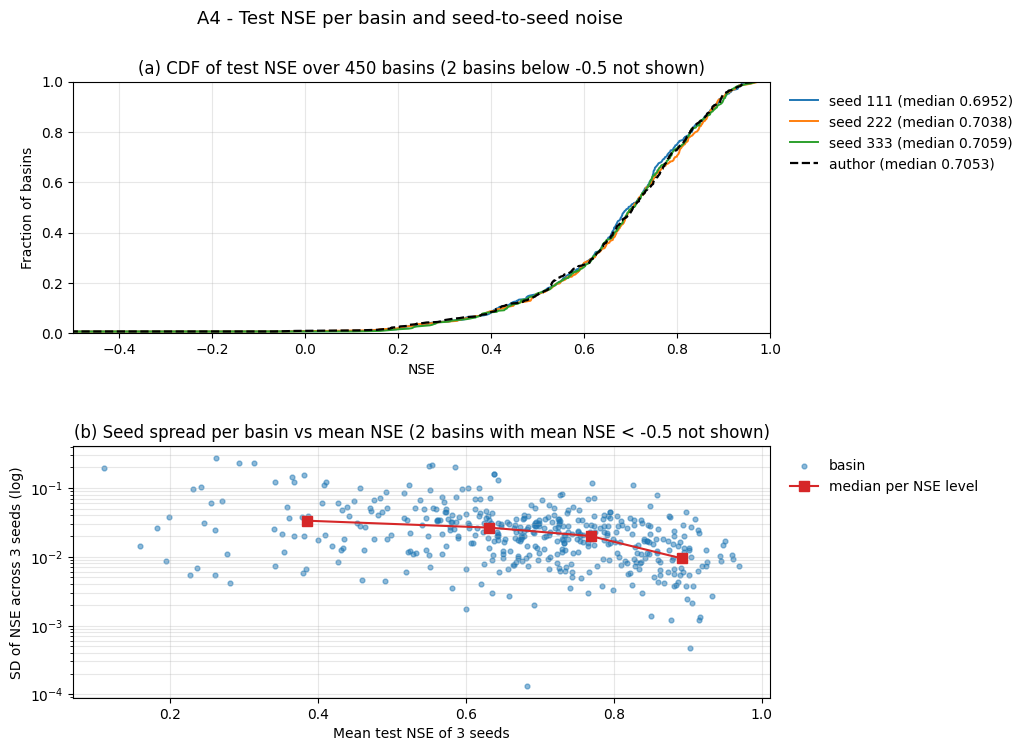

Hình: (a) Hàm phân phối tích lũy NSE test theo lưu vực: đường càng lệch phải càng tốt, trung vị từng đường ghi trong chú giải; 2 lưu vực có NSE dưới -0.5 ở ít nhất một mô hình nằm ngoài trục (742, 758). (b) Mỗi chấm là một lưu vực: trục ngang NSE trung bình 3 hạt giống, trục dọc độ lệch chuẩn NSE qua 3 hạt giống (thang log); đường đỏ là trung vị theo mức NSE. Trung vị độ lệch chuẩn là 0.0207; trung vị theo mức NSE từ thấp tới cao: 0.0335, 0.0265, 0.0200, 0.0094 => chênh lệch NSE từng lưu vực giữa các mô hình ở bước B, C phải so với mức nhiễu này.
=> Đã lưu A4_Seeds.png, A4_BasinNoise.png vào /kaggle/working/a4_compare - chạy Phần 5.


In [4]:
# %% Phần 4 - Hình
# Hai hình gộp 3 hạt giống và tác giả (thay hình riêng từng hạt giống A4_Curve_Seed{N}, A4_CDF_Seed{N}):
# A4_Seeds.png - (a) NSE validation theo epoch, (b) NSE trung vị test và điều kiện A4;
# A4_BasinNoise.png - (a) CDF NSE theo lưu vực, (b) độ lệch chuẩn qua 3 hạt giống theo mức NSE của lưu vực.
# Chữ trong hình tiếng Anh, chú giải đặt ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới hình.
import matplotlib.pyplot as plt

SEED_COLORS = {111: "#1f77b4", 222: "#ff7f0e", 333: "#2ca02c"}
AUTHOR_STYLE = {"color": "black", "ls": "--", "lw": 1.6}
CDF_XLIM = (-0.5, 1.0)  # NSE âm sâu chỉ có ở vài lưu vực qmax gần như hằng số => ghi số lưu vực bị cắt
LEGEND = {"loc": "upper left", "bbox_to_anchor": (1.01, 1), "frameon": False}


def caption(text):
    print(f"Hình: {text}")


def save(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


# Kỳ validation, test ghi trong tiêu đề hình lấy từ config.yml của run (cùng cho 3 hạt giống). Thư viện ghi ngày dạng
# dd/mm/YYYY, một giá trị hoặc danh sách nhiều đoạn (utils/config.py dòng 119-128) => lấy năm đầu và năm cuối.
cfg0 = yaml.safe_load((SEED_ROOTS[SEEDS[0]] / SEED_ENV[SEEDS[0]]["run_dir"] / "config.yml").read_text(encoding="utf-8-sig"))


def period_years(name):
    start, end = cfg0[f"{name}_start_date"], cfg0[f"{name}_end_date"]
    start, end = (start[0] if isinstance(start, list) else start), (end[-1] if isinstance(end, list) else end)
    return f"{str(start)[-4:]}-{str(end)[-4:]}"


VAL_YEARS, TEST_YEARS = period_years("validation"), period_years("test")

# Hình 1 - quá trình huấn luyện và NSE trung vị test
same_best = ("trùng epoch NSE validation cao nhất ở cả 3 hạt giống" if all(
    SEED_SUMMARY[s]["saved_epoch"] == SEED_SUMMARY[s]["true_best_epoch"] for s in SEEDS)
    else "có hạt giống lệch epoch NSE validation cao nhất (xem Phần 2)")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), gridspec_kw={"hspace": 0.45})
for s in SEEDS:
    c, sm = VAL_CURVES[s], SEED_SUMMARY[s]
    ax1.plot(c["epoch"], c["NSE trung vị validation (tệp)"], marker="o", ms=3, color=SEED_COLORS[s], label=f"seed {s}")
    best = c.loc[c["epoch"] == sm["saved_epoch"], "NSE trung vị validation (tệp)"].iloc[0]
    ax1.plot(sm["saved_epoch"], best, marker="*", ms=14, color=SEED_COLORS[s], mec="black", ls="none",
             label=f"best_model.pt seed {s} (epoch {sm['saved_epoch']})")
ax1.set(title=f"(a) Median validation NSE ({VAL_YEARS}) per epoch", xlabel="Epoch", ylabel="Median NSE")
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.grid(alpha=0.3)
ax1.legend(**LEGEND)

m, sd = nse["trung bình"], nse["độ lệch chuẩn (ddof=1)"]
ax2.axhspan(m - A4_Z_MAX * sd, m + A4_Z_MAX * sd, color="grey", alpha=0.18, label=f"seed mean ± {A4_Z_MAX:g} SD")
ax2.axhline(m, color="grey", lw=1, label=f"seed mean {m:.4f}")
ax2.axhline(AUTHOR_NSE, **AUTHOR_STYLE, label=f"author best_model.pt {AUTHOR_NSE:.4f}")
for i, s in enumerate(SEEDS):
    v = SEED_SUMMARY[s]["test_nse_median_best_model"]
    ax2.plot(i, v, "o", ms=10, color=SEED_COLORS[s], label=f"seed {s}")
    ax2.annotate(f"{v:.4f}", (i, v), xytext=(12, -4), textcoords="offset points")
ax2.set(title=f"(b) Median test NSE ({TEST_YEARS}), author z = {A4_Z:+.2f}", xticks=range(len(SEEDS)),
        xticklabels=[f"seed {s}" for s in SEEDS], xlim=(-0.5, len(SEEDS) - 0.3), ylabel="Median NSE")
ax2.grid(alpha=0.3, axis="y")
ax2.legend(**LEGEND)
fig.suptitle("A4 - Retrained Sequential Forecast LSTM with Q: 3 seeds vs author", fontsize=13, y=0.97)
save(fig, "A4_Seeds.png")
caption(f"(a) NSE trung vị validation sau mỗi epoch của 3 hạt giống; ngôi sao là epoch được lưu thành best_model.pt "
        f"(epoch {', '.join(str(SEED_SUMMARY[s]['saved_epoch']) for s in SEEDS)}), "
        f"{same_best}; đường dừng ở epoch dừng sớm. (b) NSE trung vị test của 3 hạt giống (chấm) so với best_model.pt của tác giả "
        f"(nét đứt); dải xám là trung bình ± 2 độ lệch chuẩn của 3 hạt giống. Tác giả {AUTHOR_NSE:.4f} nằm trong "
        f"[{nse['min']:.4f}, {nse['max']:.4f}]: {'có' if in_range else 'không'}; cách trung bình {abs(A4_Z):.2f} độ lệch "
        f"chuẩn => tái huấn luyện {'ĐẠT' if A4_PASS else 'KHÔNG đạt'} điều kiện A4.")

# Hình 2 - phân phối NSE theo lưu vực và nhiễu hạt giống từng lưu vực
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), gridspec_kw={"hspace": 0.45})
series = {f"seed {s}": BASIN_NOISE[f"NSE {s}"] for s in SEEDS} | {"author": BASIN_NOISE["NSE tác giả"]}
for name, v in series.items():
    v = np.sort(v.to_numpy())
    style = AUTHOR_STYLE if name == "author" else {"color": SEED_COLORS[int(name.split()[1])], "lw": 1.4}
    ax1.plot(v, np.arange(1, len(v) + 1) / len(v), **style, label=f"{name} (median {np.median(v):.4f})")
out_ids = list(BASIN_NOISE.index[BASIN_NOISE[seed_cols + ["NSE tác giả"]].min(axis=1) < CDF_XLIM[0]])
n_out = len(out_ids)
ax1.set(title=f"(a) CDF of test NSE over {len(BASIN_NOISE)} basins ({n_out} basins below {CDF_XLIM[0]:g} not shown)",
        xlabel="NSE", ylabel="Fraction of basins", xlim=CDF_XLIM, ylim=(0, 1))
ax1.grid(alpha=0.3)
ax1.legend(**LEGEND)

shown = BASIN_NOISE[BASIN_NOISE["trung bình 3 hạt giống"] >= CDF_XLIM[0]]
ax2.scatter(shown["trung bình 3 hạt giống"], shown["độ lệch chuẩn 3 hạt giống"], s=12, alpha=0.5, color="#1f77b4",
            label="basin")
lvl = shown.groupby("mức NSE", observed=True).agg(x=("trung bình 3 hạt giống", "median"),
                                                  y=("độ lệch chuẩn 3 hạt giống", "median"))
ax2.plot(lvl["x"], lvl["y"], "s-", color="#d62728", ms=7, label="median per NSE level")
ax2.set_yscale("log")
ax2.set(title=f"(b) Seed spread per basin vs mean NSE ({len(BASIN_NOISE) - len(shown)} basins with mean NSE "
              f"< {CDF_XLIM[0]:g} not shown)", xlabel="Mean test NSE of 3 seeds", ylabel="SD of NSE across 3 seeds (log)")
ax2.grid(alpha=0.3, which="both")
ax2.legend(**LEGEND)
fig.suptitle("A4 - Test NSE per basin and seed-to-seed noise", fontsize=13, y=0.97)
save(fig, "A4_BasinNoise.png")
caption(f"(a) Hàm phân phối tích lũy NSE test theo lưu vực: đường càng lệch phải càng tốt, trung vị "
        f"từng đường ghi trong chú giải; {n_out} lưu vực có NSE dưới {CDF_XLIM[0]:g} ở ít nhất một mô hình nằm ngoài trục "
        f"({', '.join(out_ids) or '-'}). "
        f"(b) Mỗi chấm là một lưu vực: trục ngang NSE trung bình 3 hạt giống, trục dọc độ lệch chuẩn NSE qua 3 hạt giống "
        f"(thang log); đường đỏ là trung vị theo mức NSE. Trung vị độ lệch chuẩn là "
        f"{BASIN_NOISE['độ lệch chuẩn 3 hạt giống'].median():.4f}; trung vị theo mức NSE từ thấp tới cao: "
        f"{', '.join(f'{v:.4f}' for v in lvl['y'])} => chênh lệch NSE từng lưu vực giữa các mô hình ở bước B, C phải so với mức nhiễu này.")
print("=> Đã lưu A4_Seeds.png, A4_BasinNoise.png vào", OUT_DIR, "- chạy Phần 5.")


# Phần 5 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
 Mỗi hạt giống một tệp SeqLSTM_Q_A4_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
 01_Evaluation_LamaHCEExt.md Mục 7, để bộ đánh giá đọc bằng --extra-contract. Cách dựng giống bộ đọc A2 của bộ đánh giá
 (01_Evaluation_LamaHCEExt.py Phần 8.2 read_a2): sim thô lấy từ test_results.p (["1D"]["xr"]["qmax_sim"], time_step = 0,
 chưa chặn âm - tester.py dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của config.yml.
 obs, persistence, diện tích, thứ tự ID lấy nguyên từ ngữ cảnh A3 (dựng lại như read_context, Phần 8.1) vì bộ đánh giá
 đòi bằng nhau từng bit giữa các run cùng nhóm (check_same_context). Kiểm lại: (1) đọc ngược tệp theo đúng các điều kiện
 của read_contract (Phần 8.3) và check_same_context; (2) NSE từng lưu vực tính lại từ test_results.p khớp test_metrics.csv
 của thư viện; (3) obs riêng của run trùng mặt nạ và giá trị với obs canonical A3.

In [5]:
# %% Phần 5 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
# Mỗi hạt giống một tệp SeqLSTM_Q_A4_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
# 01_Evaluation_LamaHCEExt.md Mục 7, để bộ đánh giá đọc bằng --extra-contract. Cách dựng giống bộ đọc A2 của bộ đánh giá
# (01_Evaluation_LamaHCEExt.py Phần 8.2 read_a2): sim thô lấy từ test_results.p (["1D"]["xr"]["qmax_sim"], time_step = 0,
# chưa chặn âm - tester.py dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của config.yml.
# obs, persistence, diện tích, thứ tự ID lấy nguyên từ ngữ cảnh A3 (dựng lại như read_context, Phần 8.1) vì bộ đánh giá
# đòi bằng nhau từng bit giữa các run cùng nhóm (check_same_context). Kiểm lại: (1) đọc ngược tệp theo đúng các điều kiện
# của read_contract (Phần 8.3) và check_same_context; (2) NSE từng lưu vực tính lại từ test_results.p khớp test_metrics.csv
# của thư viện; (3) obs riêng của run trùng mặt nạ và giá trị với obs canonical A3.
import pickle

TEST_START, TEST_END = "2014-01-01", "2017-12-31"
CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NSE_TOL = 1e-5  # NSE tính lại (float64) so với test_metrics.csv của thư viện


def basin_id(value):
    return str(int(str(value).strip()))


def contract_name(seed):
    return f"SeqLSTM_Q_A4_seed{seed}"


# (1) Ngữ cảnh A3 - như read_context của bộ đánh giá
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
physical = q * 86.4 / CTX_AREA[None, :]
ctx_checks = [("Lịch test 2014-2017", CTX_DATES.equals(pd.date_range(TEST_START, TEST_END))),
              ("Ngày nguồn persistence = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q 2013-12-31..2017-12-31", q_dates.equals(pd.date_range("2013-12-31", TEST_END))),
              ("obs, persistence khớp Q gốc / diện tích",
               np.allclose(CTX_OBS, physical[1:], rtol=1e-12, atol=1e-12, equal_nan=True)
               and np.allclose(CTX_PERS, physical[:-1], rtol=1e-12, atol=1e-12, equal_nan=True)),
              ("Đủ 451 ID", len(CTX_IDS) == 451)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError("Phần 5 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version 1")


def check_contract(path):
    # Các điều kiện của read_contract (Phần 8.3) + check_same_context (Phần 2.1) với ngữ cảnh A3; trả danh sách lỗi.
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if not isinstance(meta.get("clip_to_zero"), bool):
            errs.append("clip_to_zero không phải bool")
        lead, hz = meta.get("lead"), meta.get("forecast_horizon")
        if not (isinstance(lead, int) and isinstance(hz, int) and 1 <= lead <= hz <= 7):
            errs.append("sai lead/forecast_horizon")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("sai origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0) if meta.get("clip_to_zero") else raw, equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        if np.isinf(sim).any() or np.isinf(raw).any() or sim.shape != (len(CTX_DATES), len(CTX_IDS)):
            errs.append("sim sai kích thước hoặc có vô cực")
        if (not pd.DatetimeIndex(dates).as_unit("ns").equals(CTX_DATES)
                or tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS
                or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("khác lịch, ID hoặc diện tích ngữ cảnh A3")
        for k, ref in (("obs_mm_day", CTX_OBS), ("persistence_mm_day", CTX_PERS)):
            if not np.array_equal(d[k], ref, equal_nan=True):
                errs.append(f"{k} khác ngữ cảnh A3")
    return errs


def nse_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2) if len(o) > 1 else np.nan


# (2) Dựng và kiểm từng hạt giống
rows, CONTRACT_PATHS = [], {}
target = CTX_DATES.to_numpy().astype("datetime64[D]")
for s in SEEDS:
    run_dir = SEED_ROOTS[s] / SEED_ENV[s]["run_dir"]
    cfg_path = run_dir / "config.yml"
    clip = yaml.safe_load(cfg_path.read_text(encoding="utf-8-sig")).get("clip_targets_to_zero", []) or []
    clip = [clip] if isinstance(clip, str) else clip
    # test_results.p là pickle do chính notebook hạt giống ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (run_dir / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    keys = {basin_id(k): k for k in saved}
    if len(keys) != len(saved) or set(keys) != set(CTX_IDS):
        raise RuntimeError(f"Hạt giống {s}: ID trong test_results.p thiếu, thừa hoặc trùng")
    native, raw = np.full_like(CTX_OBS, np.nan), np.full_like(CTX_OBS, np.nan)
    for j, b in enumerate(CTX_IDS):
        xr_ = saved[keys[b]]["1D"]["xr"]
        if (not np.array_equal(xr_["time_step"].values, [0])
                or not pd.DatetimeIndex(xr_["date"].values).as_unit("ns").equals(CTX_DATES)):
            raise RuntimeError(f"Hạt giống {s}, lưu vực {b}: time_step khác [0] hoặc lịch khác kỳ test")
        native[:, j] = xr_["qmax_obs"].transpose("date", "time_step").values[:, 0]
        raw[:, j] = xr_["qmax_sim"].transpose("date", "time_step").values[:, 0]
    sim = np.maximum(raw, 0) if "qmax" in clip else raw.copy()
    meta = {"run": contract_name(s), "period": "test", "scenario": "S0", "lead": 1, "forecast_horizon": 1, "seed": s,
            "unit": "mm/day_area_gov", "config_sha256": sha256(cfg_path), "library_commit": NH_COMMIT,
            "clip_to_zero": "qmax" in clip, "selected_epoch": SEED_SUMMARY[s]["saved_epoch"],
            "source": f"03_A4_LamaHCEExt_Retrain_Seed{s} Version {SEED_VERSIONS[s]}, "
                      f"{SEED_ENV[s]['run_dir']}/test/best_model/test_results.p"}
    path = CONTRACT_DIR / f"{contract_name(s)}_test_S0_lead1.npz"
    np.savez_compressed(path, dates=target, origin_dates=target, persistence_source_dates=target - np.timedelta64(1, "D"),
                        basin_ids=np.array(CTX_IDS), area_gov_km2=CTX_AREA, obs_mm_day=CTX_OBS,
                        persistence_mm_day=CTX_PERS, sim_raw_mm_day=raw, sim_mm_day=sim, metadata_json=json.dumps(meta))
    CONTRACT_PATHS[s] = path

    # Kiểm: hợp đồng, NSE so với thư viện, obs riêng của run so với canonical
    errs = check_contract(path)
    lib = SEED_METRICS[s]["NSE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
    mine = np.array([nse_basin(native[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
    both = np.isfinite(lib) & np.isfinite(mine)
    nse_diff = float(np.max(np.abs(lib[both] - mine[both]))) if both.any() else np.nan
    nan_same = np.array_equal(np.isfinite(lib), np.isfinite(mine))
    mask_same = np.array_equal(np.isfinite(native), np.isfinite(CTX_OBS))
    both_obs = np.isfinite(native) & np.isfinite(CTX_OBS)
    rows.append({"hạt giống": s, "tệp": path.name, "MB": path.stat().st_size / 1e6,
                 "clip_to_zero": meta["clip_to_zero"], "dự báo âm trước chặn": int((raw < 0).sum()),
                 "ngày-lưu vực có sim": int(np.isfinite(sim).sum()), "lỗi hợp đồng": "; ".join(errs) or "-",
                 "max |ΔNSE| so với thư viện": nse_diff, "NaN NSE trùng thư viện": nan_same,
                 "mặt nạ obs trùng A3": mask_same,
                 "max |obs run - obs A3|": float(np.max(np.abs(native[both_obs] - CTX_OBS[both_obs]))),
                 "đạt": not errs and nse_diff <= NSE_TOL and nan_same and mask_same})
CONTRACT_TABLE = pd.DataFrame(rows)
show("Hợp đồng NPZ cho bộ đánh giá (kiểm đọc ngược và NSE tính lại)", CONTRACT_TABLE, digits=6)
if not CONTRACT_TABLE["đạt"].all():
    raise RuntimeError(f"Phần 5 CHƯA đạt (cột 'đạt' = False ở trên; ngưỡng NSE {NSE_TOL})")
print(f"=> Đạt. 3 tệp ở {CONTRACT_DIR}; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 6.")


mục,đạt
Lịch test 2014-2017,ĐẠT
Ngày nguồn persistence = ngày đích - 1,ĐẠT
ID nguồn Q trùng ID persistence,ĐẠT
Lịch nguồn Q 2013-12-31..2017-12-31,ĐẠT
"obs, persistence khớp Q gốc / diện tích",ĐẠT
Đủ 451 ID,ĐẠT


hạt giống,tệp,MB,clip_to_zero,dự báo âm trước chặn,ngày-lưu vực có sim,lỗi hợp đồng,max |ΔNSE| so với thư viện,NaN NSE trùng thư viện,mặt nạ obs trùng A3,max |obs run - obs A3|,đạt
111,SeqLSTM_Q_A4_seed111_test_S0_lead1.npz,9.964231,True,1660,652644,-,0.000000,True,True,0.000011,True
222,SeqLSTM_Q_A4_seed222_test_S0_lead1.npz,9.981163,True,2261,652644,-,0.000000,True,True,0.000011,True
333,SeqLSTM_Q_A4_seed333_test_S0_lead1.npz,9.978290,True,1978,652644,-,0.000000,True,True,0.000011,True


=> Đạt. 3 tệp ở /kaggle/working/a4_compare/contracts; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 6.


# Phần 6 - Lưu kết quả và môi trường
 Lưu 2 bảng còn lại của Phần 2, tóm tắt A4 (a4_summary.json - số liệu dùng cho báo cáo), environment.json (Input đã gắn,
 phiên bản notebook nguồn, thư viện) và manifest.csv (mọi tệp trong a4_compare kèm sha256 để bước sau kiểm khi gắn Output
 này làm Input). Bảng từng lưu vực và kiểm định ghép cặp đã lưu ở Phần 3, hình ở Phần 4, NPZ ở Phần 5.

In [6]:
# %% Phần 6 - Lưu kết quả và môi trường
# Lưu 2 bảng còn lại của Phần 2, tóm tắt A4 (a4_summary.json - số liệu dùng cho báo cáo), environment.json (Input đã gắn,
# phiên bản notebook nguồn, thư viện) và manifest.csv (mọi tệp trong a4_compare kèm sha256 để bước sau kiểm khi gắn Output
# này làm Input). Bảng từng lưu vực và kiểm định ghép cặp đã lưu ở Phần 3, hình ở Phần 4, NPZ ở Phần 5.
SEED_TABLE.to_csv(OUT_DIR / "A4_seed_table.csv", index=False)
STATS.to_csv(OUT_DIR / "A4_seed_stats.csv", index=False)

seed_pairs = PAIRED[PAIRED["họ"] == "hạt giống với hạt giống"]
A4_SUMMARY = {
    "a4_pass": bool(A4_PASS), "author_test_nse_median": AUTHOR_NSE,
    "seed_test_nse_median": {s: SEED_SUMMARY[s]["test_nse_median_best_model"] for s in SEEDS},
    "seed_test_nse_mean": float(nse["trung bình"]), "seed_test_nse_sd": float(nse["độ lệch chuẩn (ddof=1)"]),
    "seed_test_nse_range": [float(nse["min"]), float(nse["max"])], "author_z": float(A4_Z),
    "saved_epoch": {s: SEED_SUMMARY[s]["saved_epoch"] for s in SEEDS},
    "n_epochs": {s: SEED_SUMMARY[s]["n_epochs"] for s in SEEDS},
    "train_hours": {s: SEED_SUMMARY[s]["train_hours"] for s in SEEDS},
    "basins_compared": len(BASIN_NOISE),
    "basin_nse_sd_median": float(BASIN_NOISE["độ lệch chuẩn 3 hạt giống"].median()),
    "basin_nse_sd_median_by_level": {str(k): float(v) for k, v in
                                     BASIN_NOISE.groupby("mức NSE", observed=True)["độ lệch chuẩn 3 hạt giống"].median().items()},
    "author_within_seed_range_fraction": float(BASIN_NOISE["tác giả trong [min, max]"].mean()),
    "seed_pair_p_holm": {f"{r['trái']}-{r['phải']}": float(r["p Holm"]) for _, r in seed_pairs.iterrows()},
    "contracts": {s: CONTRACT_PATHS[s].relative_to(WORK_DIR).as_posix() for s in SEEDS}}
(OUT_DIR / "a4_summary.json").write_text(json.dumps(A4_SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8")

env = {"notebook": "04_A4_LamaHCEExt_Compare", "env": {k: str(v) for k, v in ENV.items()},
       "inputs": {"seeds": {s: {"notebook": f"03_A4_LamaHCEExt_Retrain_Seed{s}", "version": SEED_VERSIONS[s],
                                "input_dir": short(SEED_ROOTS[s]), "run_dir": SEED_ENV[s]["run_dir"]} for s in SEEDS},
                  "a3": {"notebook": "02_A3_LamaHCEExt_Benchmarks", "version": A3_VERSION,
                         "files": {n: {"path": short(p), "sha256": sha256(p)} for n, p in A3_PATHS.items()}},
                  "author_test_metrics": {"path": short(AUTHOR_METRICS_PATH), "sha256": sha256(AUTHOR_METRICS_PATH)}},
       "neuralhydrology_commit_of_runs": NH_COMMIT}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
MANIFEST = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": p.stat().st_size / 1e3, "sha256": sha256(p)}
                         for p in files])
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output trong {OUT_DIR.relative_to(WORK_DIR)}/ ({len(MANIFEST)} tệp, {MANIFEST['KB'].sum() / 1e3:.1f} MB)",
     MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12]), digits=1)
expected = {"A4_seed_table.csv", "A4_seed_stats.csv", "A4_seed_noise_by_basin.csv", "A4_paired_tests.csv",
            "A4_Seeds.png", "A4_BasinNoise.png", "a4_summary.json", "environment.json"} | {
            f"contracts/{CONTRACT_PATHS[s].name}" for s in SEEDS}
missing = sorted(expected - set(MANIFEST["tệp"]))
if missing:
    raise RuntimeError(f"Phần 6 CHƯA đạt: thiếu {missing}")
print(f"=> Xong A4 ({'ĐẠT' if A4_PASS else 'KHÔNG ĐẠT'} điều kiện). Tải 2 hình A4_Seeds.png, A4_BasinNoise.png về "
      "Workspace/03_Baseline/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.")


tệp,KB,sha256
A4_BasinNoise.png,188.4,f727c7252be7
A4_Seeds.png,176.9,2bf369187469
A4_paired_tests.csv,1.1,ab7b00125c14
A4_seed_noise_by_basin.csv,79.2,823e12bf4b99
A4_seed_stats.csv,0.5,467db4caf261
A4_seed_table.csv,0.7,fa839e7b783b
a4_summary.json,1.4,ede6cc3e5671
contracts/SeqLSTM_Q_A4_seed111_test_S0_lead1.npz,9964.2,55845fc937ab
contracts/SeqLSTM_Q_A4_seed222_test_S0_lead1.npz,9981.2,14afaea08355
contracts/SeqLSTM_Q_A4_seed333_test_S0_lead1.npz,9978.3,cc88ecf03378


=> Xong A4 (ĐẠT điều kiện). Tải 2 hình A4_Seeds.png, A4_BasinNoise.png về Workspace/03_Baseline/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.
